In [21]:
import matplotlib.pyplot as plt
import numpy as np
import robotics
from numpy import pi, sin, cos, tan, arctan2
dtr = pi/180
rtd = 180/pi
import control

In [2]:
plt.rcParams['font.size'] = 14
import pylab_util as PU

In [3]:
import random_bode_generator as rbg

## At least three options

## Option 1: Bode Sketching

In [4]:
G1 = rbg.random_Bode_TF()

In [5]:
G1

TransferFunction(
array([  1.        , 111.46609011]),
array([ 1.        , 21.46547359, 28.83054051,  3.70026653,  0.42512879]),
outputs=1, inputs=1)

In [8]:
import control_utils#<-- this is probably not publicly available

In [7]:
control_utils.print_factored_latex_for_TF(G1)

\frac{s +111.5}{(s^2 +0.1286 s +0.01631)(s +1.301)(s +20.04)}


$$\frac{s +111.5}{(s^2 +0.1286 s +0.01631)(s +1.301)(s +20.04)}$$

## Option 2: Bode System ID

In [10]:
G2 = rbg.random_Bode_TF()

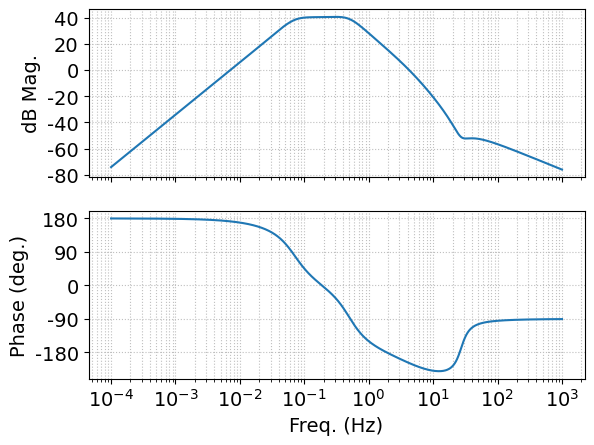

In [11]:
rbg.plot_bode_for_TF(G2)

## Option 3: Frequency Response

In [12]:
G3 = rbg.random_Bode_TF()

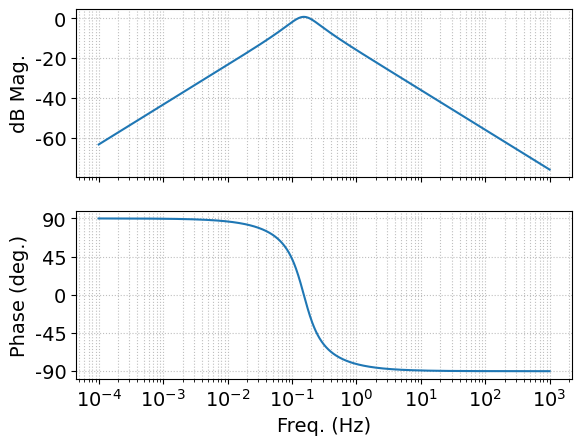

In [37]:
rbg.plot_bode_for_TF(G3)

In [13]:
f = 3
w = 2*pi*f
s = 1j*w

In [14]:
G3jw = G3(s)
G3jw

np.complex128(0.002580234614173087-0.05306439011798441j)

Estimate M from Bode:

At 3 Hz, the magnitude appears to be roughly -26 dB  and phase is roughly -85$^\circ$: 

In [39]:
10**(-26/20)

0.05011872336272722

In [23]:
M = np.abs(G3jw)
phi = np.angle(G3jw)
M

np.float64(0.05312708451682455)

Phi estimate from Bode plot

In [38]:
-85*pi/180

-1.4835298641951802

Exact phi from TF:

In [24]:
phi

np.float64(-1.5222099968440836)

In [32]:
t = np.arange(0,10,0.01)

In [33]:
u = np.sin(w*t)

In [34]:
y_ss = M*np.sin(w*t+phi)

In [35]:
to, y_full = control.forced_response(G3,t,u)

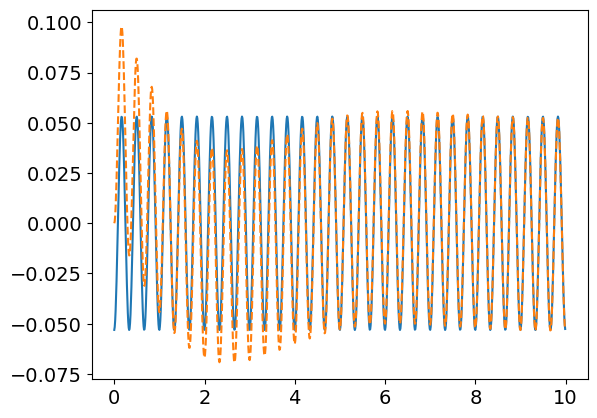

In [36]:
plt.figure()
plt.plot(t,y_ss,t,y_full,'--')